# 03 - Generate synthetic images + quality control

1. (Tuỳ chọn) So sánh các snapshot còn giữ để chọn generator.
2. Sinh ảnh cho các lớp thiểu số từ snapshot đã chọn (`G_ema`, có điều kiện theo lớp).
3. Kiểm tra chất lượng trên feature ResNet-50 (ImageNet):
   - Memorization: mỗi ảnh giả <-> ảnh train thật gần nhất cùng lớp, gắn cờ nếu gần hơn mức thường gặp giữa
     hai lesion thật khác nhau (percentile `NN_PCT`).
   - Precision / Recall / Density / Coverage (Naeem et al., 2020), k = 5.
4. Đánh giá bổ sung luôn kèm mốc real-real (real val so với real train, cùng số mẫu):
   - FID tổng thể (Heusel et al., 2017) và KID theo lớp (Bińkowski et al., 2018) trên feature Inception-v3,
     thêm DINOv2 nếu tải được (Stein et al., 2023).
   - Phân biệt thật/giả: linear probe + ResNet-18 fine-tune; AUC ~0.5 = khó phân biệt.
5. Xuất bộ ảnh tổng hợp có version + manifest cho notebook classifier.

**Chạy trên:** GPU + Internet (tải repo StyleGAN3, trọng số ResNet/Inception, DINOv2).

**Input cần Add:** output của `01_prepare_gan_data`, output (version mới nhất) của `02_train_gan`,
và dataset `DSR301m` (để lấy `HAM10000_lesion_split_seed42_v2.csv` -> ảnh real val làm mốc so sánh, không dùng test).

**Output:** `/kaggle/working/synthetic_v2/`
```
images/syn_<dx>_s<seed>.png      # 256x256, cùng định dạng với real_sq256/
synthetic_manifest.csv           # mỗi dòng 1 ảnh: lớp, seed, snapshot, nn_sim, flag_memorized...
grid_<dx>.png, nn_pairs_<dx>.png # xem bằng mắt
snapshot_comparison.csv          # nếu COMPARE_SNAPSHOTS
generator_info.json              # snapshot + SHA-256, cấu hình, PRDC, ngưỡng memorization, mọi chỉ số chất lượng
quality_metrics.csv              # bảng FID/KID/AUC kèm mốc real-real
```

In [ ]:
import os, sys, glob, json, math, time, hashlib, subprocess
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image

# ===== CONFIG =====
SNAPSHOT          = None        # None = snapshot mới nhất; hoặc tên file, vd "network-snapshot-002400.pkl"
COMPARE_SNAPSHOTS = True        # so sánh nhanh các snapshot còn giữ trước khi sinh bộ chính
N_COMPARE         = 200         # số ảnh/lớp khi so sánh
MINORITY          = ["akiec", "df", "vasc"]   # thêm "bcc" nếu muốn
POOL_MULT         = 3           # sinh đủ cho tỷ lệ synthetic:real tối đa = 3x
MIN_POOL          = 500         # ... hoặc tối thiểu 500 ảnh/lớp (cân bằng "tương đối")
EXTRA             = 1.2         # dư 20% để bù ảnh bị loại vì memorization
TRUNC             = 1.0         # 1.0 = không truncation (giữ đa dạng)
SEED_BASE         = 0
NN_PCT            = 99          # ngưỡng memorization: percentile của NN-sim giữa các lesion thật khác nhau
K_PRDC            = 5
VERSION           = "synthetic_v2"

# --- Đánh giá bổ sung ---
SPLIT_CSV_NAME    = "HAM10000_lesion_split_seed42_v2.csv"
USE_DINOV2        = True        # feature DINOv2 ViT-S/14 (tải qua torch.hub); lỗi tải -> tự bỏ qua
KID_SUBSETS       = 100
N_BOOT            = 5           # số bộ ảnh giả độc lập để báo mean +- std (bộ ảnh chính)
N_BOOT_COMPARE    = 1           # ... khi so sánh snapshot (cho nhanh)
RUN_DETECTOR      = True        # phân biệt thật/giả
DET_EPOCHS        = 5

INPUT_ROOT = "/kaggle/input"
OUT        = f"/kaggle/working/{VERSION}"
REPO       = "/tmp/stylegan3"
os.makedirs(f"{OUT}/images", exist_ok=True)
device = torch.device("cuda")
assert torch.cuda.is_available(), "Bật GPU: Settings -> Accelerator -> GPU"

In [ ]:
if not os.path.exists(REPO):
    !git clone -q https://github.com/NVlabs/stylegan3.git {REPO}
!pip install -q ninja
def patch_stylegan3(repo):
    """Vá StyleGAN3 cho Python 3.12+/PyTorch 2.x mới (Kaggle). Chạy lại nhiều lần không sao."""
    import os

    def sub(rel, old, new):
        p = os.path.join(repo, rel)
        s = open(p).read()
        if new in s:
            return "đã vá"
        assert old in s, f"{rel}: không tìm thấy đoạn cần vá -> repo đã thay đổi"
        open(p, "w").write(s.replace(old, new))
        return "vá xong"

    report = {}
    # 1) PyTorch mới không thêm thư mục build vào sys.path -> dùng module mà load() trả về
    report["custom_ops: load"] = sub(
        "torch_utils/custom_ops.py",
        "            torch.utils.cpp_extension.load(name=module_name, build_directory=cached_build_dir,",
        "            module = torch.utils.cpp_extension.load(name=module_name, build_directory=cached_build_dir,")
    report["custom_ops: load (else)"] = sub(
        "torch_utils/custom_ops.py",
        "            torch.utils.cpp_extension.load(name=module_name, verbose=verbose_build, sources=sources, **build_kwargs)",
        "            module = torch.utils.cpp_extension.load(name=module_name, verbose=verbose_build, sources=sources, **build_kwargs)")
    report["custom_ops: import"] = sub(
        "torch_utils/custom_ops.py",
        "        module = importlib.import_module(module_name)\n",
        "        if module is None or not hasattr(module, '__name__'):\n"
        "            module = importlib.import_module(module_name)\n")
    # 2) distutils đã bị xoá khỏi Python 3.12+
    report["dnnlib: strtobool"] = sub(
        "dnnlib/util.py",
        "from distutils.util import strtobool\n",
        "def strtobool(v):\n"
        "    v = str(v).lower()\n"
        "    if v in ('y', 'yes', 't', 'true', 'on', '1'): return 1\n"
        "    if v in ('n', 'no', 'f', 'false', 'off', '0'): return 0\n"
        "    raise ValueError(f'invalid truth value {v!r}')\n")
    # 3) pkg_resources đang bị gỡ khỏi setuptools -> dùng packaging
    for rel in ["torch_utils/ops/conv2d_gradfix.py", "torch_utils/ops/grid_sample_gradfix.py"]:
        report[rel] = sub(rel, "from pkg_resources import parse_version",
                          "from packaging.version import parse as parse_version")
    # 4) torch.utils.data.Sampler không còn nhận tham số dataset (PyTorch 2.2+)
    report["misc: InfiniteSampler"] = sub(
        "torch_utils/misc.py",
        "        super().__init__(dataset)\n        self.dataset = dataset",
        "        super().__init__()\n        self.dataset = dataset")
    # 5) API TorchScript nội bộ -> op aten công khai (ADA dùng grid_sample ở mọi bước train)
    report["grid_sample_gradfix: op"] = sub(
        "torch_utils/ops/grid_sample_gradfix.py",
        "        op = torch._C._jit_get_operation('aten::grid_sampler_2d_backward')\n"
        "        if _use_pytorch_1_12_api:\n"
        "            op = op[0]\n",
        "        op = torch.ops.aten.grid_sampler_2d_backward\n")
    report["grid_sample_gradfix: mask"] = sub(
        "torch_utils/ops/grid_sample_gradfix.py",
        "            output_mask = (ctx.needs_input_grad[1], ctx.needs_input_grad[2])",
        "            output_mask = [bool(ctx.needs_input_grad[1]), bool(ctx.needs_input_grad[2])]")
    # 6) tham số only_inputs của autograd.grad đã deprecated (mặc định vẫn là True)
    p = os.path.join(repo, "training/loss.py")
    s = open(p).read()
    report["loss: only_inputs"] = "vá xong" if ", only_inputs=True" in s else "đã vá"
    open(p, "w").write(s.replace(", only_inputs=True", ""))
    return report


FALLBACK_MARK = "# KAGGLE_REF_FALLBACK"

def enable_ref_fallback(repo):
    """Nếu CUDA plugin không build/nạp được: dùng bản PyTorch thuần thay vì dừng (chậm hơn)."""
    import os
    code = (f"\n\n{FALLBACK_MARK}\n"
            "_kaggle_orig_init = _init\n"
            "_kaggle_failed = False\n"
            "def _init():\n"
            "    global _kaggle_failed\n"
            "    if _kaggle_failed:\n"
            "        return False\n"
            "    try:\n"
            "        return _kaggle_orig_init()\n"
            "    except Exception as e:\n"
            "        _kaggle_failed = True\n"
            "        print(f'[fallback] {__name__}: CUDA plugin lỗi ({type(e).__name__}: {e}) -> dùng bản PyTorch thuần')\n"
            "        return False\n")
    for name in ["bias_act", "upfirdn2d", "filtered_lrelu"]:
        p = os.path.join(repo, "torch_utils", "ops", f"{name}.py")
        s = open(p).read()
        if FALLBACK_MARK not in s:
            open(p, "w").write(s + code)



patch_stylegan3(REPO)
enable_ref_fallback(REPO)
sys.path.insert(0, REPO)
import legacy, dnnlib   # cần để unpickle snapshot

def find(pattern):
    return sorted(glob.glob(os.path.join(INPUT_ROOT, "**", pattern), recursive=True))

train_csv = find("gan_train_manifest.csv");  assert train_csv, "Thiếu output notebook 01"
real_dir  = [d for d in find("real_sq*") if os.path.isdir(d)][0]
class_map = json.load(open(find("class_map.json")[0]))
prep_info = json.load(open(find("prep_info.json")[0]))
prog_path = find("checkpoints/progress.json"); assert prog_path, "Thiếu output notebook 02"
ckpt_dir  = os.path.dirname(prog_path[0])
progress  = json.load(open(prog_path[0]))

train = pd.read_csv(train_csv[0])
train["path"] = real_dir + "/" + train.image_id + ".png"
snaps = sorted(glob.glob(f"{ckpt_dir}/network-snapshot-*.pkl"))

# Split manifest (chỉ để lấy ảnh real VAL làm mốc so sánh; không dùng test)
split_hits = find(SPLIT_CSV_NAME)
assert split_hits, f"Thiếu {SPLIT_CSV_NAME} — Add Input dataset DSR301m."
split_df = pd.read_csv(split_hits[0])
assert hashlib.sha256(open(split_hits[0], "rb").read()).hexdigest() == prep_info["split_manifest_sha256"],     "Split manifest khác bản đã dùng ở notebook 01!"
val = split_df[split_df.split == "val"].sort_values("image_id").reset_index(drop=True)
val["path"] = real_dir + "/" + val.image_id + ".png"
assert set(train.image_id) == set(split_df[split_df.split == "train"].image_id)
print(f"Real train: {len(train):,} | real val: {len(val):,} (mốc so sánh)")
print("Real dir:", real_dir)
print("GAN đã train tổng:", progress["total_kimg"], "kimg | snapshot có sẵn:", [os.path.basename(s) for s in snaps])
assert progress["data_zip_sha256"] == prep_info["gan_train_zip_sha256"], "Snapshot không được train trên đúng gan_train.zip này!"

Real train: 6,981 | real val: 1,532 (mốc so sánh)
Real dir: /kaggle/input/notebooks/kietvgpham/01-prepare-gan-data/real_sq256
GAN đã train tổng: 3320 kimg | snapshot có sẵn: ['network-snapshot-000520.pkl', 'network-snapshot-001000.pkl', 'network-snapshot-001480.pkl', 'network-snapshot-002400.pkl', 'network-snapshot-003240.pkl', 'network-snapshot-003280.pkl', 'network-snapshot-003320.pkl']


## 1a. Hàm dùng chung: nạp generator, sinh ảnh, trích feature, PRDC

In [3]:
def load_G(pkl):
    with open(pkl, "rb") as f:
        G = legacy.load_network_pkl(f)["G_ema"]
    return G.eval().requires_grad_(False).to(device)

@torch.no_grad()
def generate(G, class_idx, seeds, trunc=TRUNC, bs=32):
    out = []
    for i in range(0, len(seeds), bs):
        s = seeds[i:i + bs]
        z = torch.from_numpy(np.stack([np.random.RandomState(x).randn(G.z_dim) for x in s])).float().to(device)
        c = torch.zeros(len(s), G.c_dim, device=device); c[:, class_idx] = 1
        img = G(z, c, truncation_psi=trunc, noise_mode="const")
        out.extend((img.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8).cpu().numpy())
    return out

from torchvision.models import resnet50, ResNet50_Weights
fe = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2); fe.fc = nn.Identity()
fe = fe.eval().to(device)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

@torch.no_grad()
def feats(arrs, bs=64):
    out = []
    for i in range(0, len(arrs), bs):
        x = torch.from_numpy(np.stack(arrs[i:i + bs])).to(device).permute(0, 3, 1, 2).float() / 255
        x = F.interpolate(x, size=224, mode="bilinear", antialias=True, align_corners=False)
        out.append(F.normalize(fe((x - MEAN) / STD), dim=1))
    return torch.cat(out)

def load_real(paths):
    return [np.asarray(Image.open(p).convert("RGB")) for p in paths]

def prdc(real, fake, k=K_PRDC):
    d_rr = torch.cdist(real, real); d_ff = torch.cdist(fake, fake); d_rf = torch.cdist(real, fake)
    r_real = d_rr.kthvalue(k + 1, dim=1).values        # +1 vì khoảng cách tới chính nó = 0
    r_fake = d_ff.kthvalue(k + 1, dim=1).values
    inside = d_rf < r_real[:, None]
    return {"precision": inside.any(0).float().mean().item(),
            "recall":    (d_rf < r_fake[None, :]).any(1).float().mean().item(),
            "density":   (inside.sum(0).float() / k).mean().item(),
            "coverage":  (d_rf.min(1).values < r_real).float().mean().item()}

# Feature ảnh thật (train) cho các lớp thiểu số + ngưỡng memorization từ cặp lesion thật khác nhau
real_feats, real_rows, thresholds = {}, {}, {}
for dx in MINORITY:
    rows = train[train.dx == dx].reset_index(drop=True)
    R = feats(load_real(rows.path))
    sim = R @ R.T
    les = rows.lesion_id.values
    sim[torch.from_numpy(les[:, None] == les[None, :]).to(device)] = -1   # bỏ chính nó + ảnh cùng lesion
    rr_nn = sim.max(1).values.cpu().numpy()
    real_feats[dx], real_rows[dx] = R, rows
    thresholds[dx] = float(np.percentile(rr_nn, NN_PCT))
    print(f"{dx:6s} real={len(rows):4d}  NN-sim giữa lesion khác nhau: median {np.median(rr_nn):.3f} | "
          f"p{NN_PCT} = {thresholds[dx]:.3f} (ngưỡng)")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 228MB/s]


akiec  real= 222  NN-sim giữa lesion khác nhau: median 0.872 | p99 = 0.941 (ngưỡng)
df     real=  71  NN-sim giữa lesion khác nhau: median 0.802 | p99 = 0.920 (ngưỡng)
vasc   real=  99  NN-sim giữa lesion khác nhau: median 0.801 | p99 = 0.946 (ngưỡng)


## 1b. Feature cho FID / KID + mốc real-real

- **Inception-v3 (torchvision, ImageNet):** feature 2048 chiều như FID chuẩn. Giá trị chỉ dùng so sánh nội bộ
  (cùng số mẫu, cùng feature), không so với FID công bố trong các bài báo.
- **DINOv2 ViT-S/14:** feature tự giám sát, thường khớp đánh giá của người hơn Inception (Stein et al., 2023).
- **Mốc real-real:** real val so với real train, cùng số mẫu như bộ ảnh giả. Đây là mức tốt nhất có thể kỳ vọng:
  ảnh giả có FID/KID gần mốc này là tốt.
- Bộ ảnh giả để tính FID tổng thể có đúng thành phần lớp như real val (1,532 ảnh) -> so được trực tiếp với mốc.

In [ ]:
import numpy as np
import scipy.linalg


def _sqrtm(m):
    # SciPy cũ trả (matrix, err) khi disp=False, SciPy mới bỏ tham số disp
    r = scipy.linalg.sqrtm(m)
    return r[0] if isinstance(r, tuple) else r


def fid_from_feats(a, b):
    """Fréchet distance giữa hai tập feature (n*d). Dùng để so sánh nội bộ, không so với số liệu FID công bố."""
    a = np.asarray(a, dtype=np.float64); b = np.asarray(b, dtype=np.float64)
    mu1, mu2 = a.mean(0), b.mean(0)
    s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    covmean = _sqrtm(s1 @ s2)
    if not np.isfinite(covmean).all():
        eps = np.eye(s1.shape[0]) * 1e-6
        covmean = _sqrtm((s1 + eps) @ (s2 + eps))
    covmean = covmean.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))


def kid_from_feats(a, b, n_subsets=100, subset_size=1000, seed=0):
    """Kernel Inception Distance (Bińkowski et al., 2018): MMD^2 không chệch, kernel đa thức bậc 3.
    Trả về (mean, std) qua các tập con, dùng được khi ít mẫu."""
    a = np.asarray(a, dtype=np.float64); b = np.asarray(b, dtype=np.float64)
    rng = np.random.default_rng(seed)
    d = a.shape[1]
    m = min(subset_size, len(a), len(b))
    assert m >= 2, "KID cần ít nhất 2 mẫu mỗi bên"
    vals = []
    for _ in range(n_subsets):
        x = a[rng.choice(len(a), m, replace=False)]
        y = b[rng.choice(len(b), m, replace=False)]
        kxx = (x @ x.T / d + 1) ** 3
        kyy = (y @ y.T / d + 1) ** 3
        kxy = (x @ y.T / d + 1) ** 3
        mmd = ((kxx.sum() - np.trace(kxx)) / (m * (m - 1))
               + (kyy.sum() - np.trace(kyy)) / (m * (m - 1))
               - 2 * kxy.mean())
        vals.append(mmd)
    return float(np.mean(vals)), float(np.std(vals))


def probe_auc(train_x, train_y, test_x, test_y, seed=0):
    """Linear probe thật/giả: logistic regression trên feature cố định -> AUC trên tập giữ lại."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    from sklearn.metrics import roc_auc_score
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0, random_state=seed))
    clf.fit(train_x, train_y)
    return float(roc_auc_score(test_y, clf.predict_proba(test_x)[:, 1]))



class Extractor:
    def __init__(self, name):
        self.name = name
        if name == "inception":
            from torchvision.models import inception_v3, Inception_V3_Weights
            m = inception_v3(weights=Inception_V3_Weights.IMAGENET1K_V1)   # transform_input=True: nhận input chuẩn hoá ImageNet
            m.fc = nn.Identity(); self.size = 299
        elif name == "dinov2":
            m = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14", verbose=False); self.size = 224
        self.m = m.eval().to(device)

    @torch.no_grad()
    def __call__(self, arrs, bs=64):
        out = []
        for i in range(0, len(arrs), bs):
            x = torch.from_numpy(np.stack(arrs[i:i + bs])).to(device).permute(0, 3, 1, 2).float() / 255
            x = F.interpolate(x, size=self.size, mode="bilinear", antialias=True, align_corners=False)
            out.append(self.m((x - MEAN) / STD).float().cpu())
        return torch.cat(out).numpy().astype(np.float64)

    def from_paths(self, paths, chunk=512):
        return np.concatenate([self(load_real(paths[i:i + chunk])) for i in range(0, len(paths), chunk)])

extractors = {"inception": Extractor("inception")}
if USE_DINOV2:
    try:
        extractors["dinov2"] = Extractor("dinov2")
    except Exception as e:
        print(f"Không tải được DINOv2 ({type(e).__name__}: {e}) -> chỉ dùng Inception")
print("Feature:", list(extractors))

CLASSES  = sorted(class_map, key=class_map.get)
n_val_by = val.dx.value_counts().to_dict()               # thành phần lớp của real val
t0 = time.time()
real_tr_f = {k: ex.from_paths(train.path.tolist()) for k, ex in extractors.items()}
real_va_f = {k: ex.from_paths(val.path.tolist())   for k, ex in extractors.items()}
tr_mask = {c: (train.dx == c).values for c in CLASSES}
va_mask = {c: (val.dx == c).values for c in CLASSES}
print(f"Feature ảnh thật xong ({time.time() - t0:.0f}s)")

# Mốc thật–thật
REF = {}
for k in extractors:
    REF[f"FID_{k}"] = fid_from_feats(real_va_f[k], real_tr_f[k])
    for c in MINORITY:
        m_, s_ = kid_from_feats(real_va_f[k][va_mask[c]], real_tr_f[k][tr_mask[c]], n_subsets=KID_SUBSETS)
        REF[f"KIDx1000_{k}_{c}"] = 1000 * m_
print("Mốc thật–thật (real val vs real train):")
print(json.dumps({k: round(v, 3) for k, v in REF.items()}, indent=1))

def eval_fake_sets(G, seed0, n_boot):
    """Sinh n_boot bộ ảnh giả có thành phần lớp như real val, trả FID tổng thể + KID theo lớp (mean, std)."""
    res = {}
    for b in range(n_boot):
        fk = {k: [] for k in extractors}; cls_of = []
        for c in CLASSES:
            n = n_val_by.get(c, 0)
            if n == 0: continue
            seeds = list(range(seed0 + b * 50_000 + class_map[c] * 5_000, seed0 + b * 50_000 + class_map[c] * 5_000 + n))
            imgs = generate(G, class_map[c], seeds)
            for k, ex in extractors.items():
                fk[k].append(ex(imgs))
            cls_of += [c] * n
        cls_of = np.array(cls_of)
        for k in extractors:
            F_all = np.concatenate(fk[k])
            res.setdefault(f"FID_{k}", []).append(fid_from_feats(F_all, real_tr_f[k]))
            for c in MINORITY:
                m_, _ = kid_from_feats(F_all[cls_of == c], real_tr_f[k][tr_mask[c]], n_subsets=KID_SUBSETS, seed=b)
                res.setdefault(f"KIDx1000_{k}_{c}", []).append(1000 * m_)
    return {k: (float(np.mean(v)), float(np.std(v))) for k, v in res.items()}

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 196MB/s] 


Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 668MB/s]


Feature: ['inception', 'dinov2']
Feature ảnh thật xong (750s)
Mốc thật–thật (real val vs real train):
{
 "FID_inception": 14.093,
 "KIDx1000_inception_akiec": 2.2,
 "KIDx1000_inception_df": 15.935,
 "KIDx1000_inception_vasc": 8.697,
 "FID_dinov2": 23.475,
 "KIDx1000_dinov2_akiec": 2242.492,
 "KIDx1000_dinov2_df": 7309.515,
 "KIDx1000_dinov2_vasc": 9294.597
}


## 2. (Tuỳ chọn) So sánh các snapshot

Mỗi snapshot sinh `N_COMPARE` ảnh/lớp (seed riêng, không trùng bộ chính).  
**Precision/density** cao = ảnh giống ảnh thật; **recall/coverage** cao = đa dạng, phủ được phân phối thật;
**mem_rate** = tỷ lệ ảnh vượt ngưỡng memorization.  
Đây là gợi ý, hãy kết hợp với việc xem lưới ảnh ở notebook 02 rồi đặt `SNAPSHOT` ở cell config.

In [5]:
if COMPARE_SNAPSHOTS and len(snaps) > 1:
    rows, qrows = [], []
    for pkl in snaps:
        G = load_G(pkl)
        for dx in MINORITY:
            imgs = generate(G, class_map[dx], list(range(900_000, 900_000 + N_COMPARE)))
            S = feats(imgs)
            m = prdc(real_feats[dx], S)
            nn_sim = (S @ real_feats[dx].T).max(1).values.cpu().numpy()
            rows.append({"snapshot": os.path.basename(pkl), "dx": dx, **{k: round(v, 3) for k, v in m.items()},
                         "mem_rate": round(float((nn_sim > thresholds[dx]).mean()), 3)})
        q = eval_fake_sets(G, seed0=3_000_000, n_boot=N_BOOT_COMPARE)
        qrows.append({"snapshot": os.path.basename(pkl), **{k: round(v[0], 3) for k, v in q.items()}})
        del G; torch.cuda.empty_cache()
    comp = pd.DataFrame(rows)
    comp.to_csv(f"{OUT}/snapshot_comparison.csv", index=False)
    display(comp.pivot(index="snapshot", columns="dx", values=["precision", "coverage", "mem_rate"]))
    qcomp = pd.DataFrame(qrows)
    qcomp = pd.concat([qcomp, pd.DataFrame([{"snapshot": "MỐC thật–thật", **{k: round(v, 3) for k, v in REF.items()}}])])
    qcomp.to_csv(f"{OUT}/snapshot_comparison_fid_kid.csv", index=False)
    print("FID/KID theo snapshot (càng gần dòng MỐC càng tốt; KID ×1000):")
    display(qcomp.set_index("snapshot"))
else:
    print("Bỏ qua so sánh (tắt hoặc chỉ có 1 snapshot).")

Setting up PyTorch plugin "bias_act_plugin"... Done.
Setting up PyTorch plugin "upfirdn2d_plugin"... Done.


precision               coverage                \
dx                              akiec     df   vasc    akiec     df   vasc   
snapshot                                                                     
network-snapshot-000520.pkl     0.660  0.735  0.540    0.315  0.437  0.263   
network-snapshot-001000.pkl     0.645  0.490  0.355    0.342  0.549  0.263   
network-snapshot-001480.pkl     0.635  0.775  0.705    0.473  0.648  0.424   
network-snapshot-002400.pkl     0.745  0.865  0.760    0.423  0.831  0.667   
network-snapshot-003240.pkl     0.780  0.935  0.850    0.590  0.901  0.798   
network-snapshot-003280.pkl     0.790  0.940  0.835    0.563  0.944  0.838   
network-snapshot-003320.pkl     0.815  0.885  0.805    0.559  0.915  0.727   

                            mem_rate              
dx                             akiec     df vasc  
snapshot                                          
network-snapshot-000520.pkl    0.005  0.000  0.0  
network-snapshot-001000.pkl    0.000  0.010  0.0  
network-snapshot-001480.pkl    0.005  0.000  0.0  
network-snapshot-002400.pkl    0.005  0.000  0.0  
network-snapshot-003240.pkl    0.000  0.005  0.0  
network-snapshot-003280.pkl    0.000  0.000  0.0  
network-snapshot-003320.pkl    0.010  0.000  0.0

FID/KID theo snapshot (càng gần dòng MỐC càng tốt; KID ×1000):


,FID_inception,KIDx1000_inception_akiec,KIDx1000_inception_df,KIDx1000_inception_vasc,FID_dinov2,KIDx1000_dinov2_akiec,KIDx1000_dinov2_df,KIDx1000_dinov2_vasc
snapshot,,,,,,,,
network-snapshot-000520.pkl,86.170,77.422,63.242,77.372,881.193,128719.658,121608.503,148605.658
network-snapshot-001000.pkl,63.250,29.064,63.088,61.887,596.669,72441.519,88492.201,96394.211
network-snapshot-001480.pkl,53.992,39.715,43.606,40.819,505.933,65175.998,72112.302,80127.724
network-snapshot-002400.pkl,45.448,30.494,33.658,51.743,492.563,62940.885,79250.293,89314.356
network-snapshot-003240.pkl,31.157,20.877,16.718,19.782,344.913,45984.578,34681.966,57159.261
network-snapshot-003280.pkl,32.488,32.580,22.413,23.774,339.466,39674.779,36268.186,70185.716
network-snapshot-003320.pkl,33.140,35.701,41.130,28.386,346.242,42638.202,45633.893,75441.655
MỐC thật–thật,14.093,2.200,15.935,8.697,23.475,2242.492,7309.515,9294.597


## 3. Sinh bộ ảnh chính từ snapshot đã chọn

In [6]:
pkl = os.path.join(ckpt_dir, SNAPSHOT) if SNAPSHOT else os.path.join(ckpt_dir, progress["latest_snapshot"])
assert os.path.exists(pkl), pkl
snap_name = os.path.basename(pkl)
snap_kimg = int(snap_name.split("-")[-1].split(".")[0])
G = load_G(pkl)
assert G.c_dim == len(class_map) and G.img_resolution == prep_info["res"], (G.c_dim, G.img_resolution)
print("Generator:", snap_name, "| z_dim", G.z_dim, "| c_dim", G.c_dim, "| res", G.img_resolution)

records, syn_imgs = [], {}
for dx in MINORITY:
    n_real = int((train.dx == dx).sum())
    n_pool = math.ceil(max(POOL_MULT * n_real, MIN_POOL) * EXTRA)
    seeds = list(range(SEED_BASE + class_map[dx] * 100_000, SEED_BASE + class_map[dx] * 100_000 + n_pool))
    t0 = time.time()
    imgs = generate(G, class_map[dx], seeds)
    syn_imgs[dx] = imgs
    for s, im in zip(seeds, imgs):
        iid = f"syn_{dx}_s{s:06d}"
        Image.fromarray(im).save(f"{OUT}/images/{iid}.png")
        records.append({"image_id": iid, "dx": dx, "class_idx": class_map[dx], "split": "train", "source": "gan",
                        "path": f"images/{iid}.png", "generator_snapshot": snap_name,
                        "generator_total_kimg": snap_kimg, "seed": s, "truncation": TRUNC})
    print(f"{dx:6s} real={n_real:4d} → sinh {n_pool:4d} ảnh ({time.time() - t0:.0f}s)")
syn = pd.DataFrame(records)

Generator: network-snapshot-003320.pkl | z_dim 512 | c_dim 7 | res 256
akiec  real= 222 → sinh  800 ảnh (36s)
df     real=  71 → sinh  600 ảnh (27s)
vasc   real=  99 → sinh  600 ảnh (29s)


## 4a. Memorization check + PRDC trên bộ ảnh chính

In [7]:
prdc_res, parts = {}, []
for dx in MINORITY:
    S = feats(syn_imgs[dx])
    sim = S @ real_feats[dx].T
    nn_sim, nn_idx = sim.max(1)
    nn_sim, nn_idx = nn_sim.cpu().numpy(), nn_idx.cpu().numpy()
    sub = syn[syn.dx == dx].copy()
    sub["nn_image_id"]    = real_rows[dx].image_id.values[nn_idx]
    sub["nn_lesion_id"]   = real_rows[dx].lesion_id.values[nn_idx]
    sub["nn_sim"]         = nn_sim.round(4)
    sub["flag_memorized"] = nn_sim > thresholds[dx]
    parts.append(sub)
    prdc_res[dx] = {k: round(v, 4) for k, v in prdc(real_feats[dx], S).items()}
    print(f"{dx:6s} {prdc_res[dx]} | gắn cờ memorization: {int(sub.flag_memorized.sum())}/{len(sub)}")
syn = pd.concat(parts).reset_index(drop=True)

akiec  {'precision': 0.8262, 'recall': 0.2658, 'density': 0.698, 'coverage': 0.7748} | gắn cờ memorization: 6/800
df     {'precision': 0.9067, 'recall': 0.2113, 'density': 0.8047, 'coverage': 0.9718} | gắn cờ memorization: 1/600
vasc   {'precision': 0.8017, 'recall': 0.2929, 'density': 0.6563, 'coverage': 0.899} | gắn cờ memorization: 0/600


## 4b. FID / KID của snapshot đã chọn (N_BOOT bộ ảnh giả độc lập)

Báo cáo dạng mean +- std qua `N_BOOT` bộ ảnh giả, đặt cạnh mốc real-real.  
Với DF/VASC chỉ có ~20-50 ảnh val, KID theo lớp dao động lớn -> đọc theo xu hướng, không theo chữ số thập phân.

In [8]:
q_final = eval_fake_sets(G, seed0=2_000_000, n_boot=N_BOOT)   # dải seed riêng, không trùng bộ ảnh chính / so sánh
qm_rows = []
for k, (m_, s_) in q_final.items():
    qm_rows.append({"metric": k, "fake_mean": round(m_, 3), "fake_std": round(s_, 3),
                    "ref_real_val_vs_train": round(REF[k], 3), "ratio_to_ref": round(m_ / REF[k], 2) if REF[k] > 0 else None})
qm = pd.DataFrame(qm_rows)
display(qm)

,metric,fake_mean,fake_std,ref_real_val_vs_train,ratio_to_ref
0,FID_inception,34.206,0.750,14.093,2.43
1,KIDx1000_inception_akiec,28.695,6.760,2.200,13.04
2,KIDx1000_inception_df,44.822,17.204,15.935,2.81
3,KIDx1000_inception_vasc,27.184,7.930,8.697,3.13
4,FID_dinov2,348.480,6.130,23.475,14.84
5,KIDx1000_dinov2_akiec,35229.872,2823.914,2242.492,15.71
6,KIDx1000_dinov2_df,43996.502,8014.501,7309.515,6.02
7,KIDx1000_dinov2_vasc,71984.572,10422.824,9294.597,7.74


## 4c. Phân biệt thật / giả (lớp thiểu số)

- **Train:** ảnh real train vs số ảnh giả bằng nhau (mỗi lớp). **Đánh giá:** ảnh real val vs ảnh giả *chưa dùng*.
- **Linear probe** trên feature cố định (ResNet-50, Inception, DINOv2): đo khác biệt ở mức "nội dung".
- **ResNet-18 fine-tune**: nhạy cả với dấu vết cấp thấp (texture, tần số cao) của GAN.
- Đọc AUC (tham khảo): **~0.5-0.65:** khó phân biệt | **0.65-0.85:** có khác biệt | **>0.85:** dễ nhận ra  
  -> classifier chính có thể học "dấu vết GAN" thay vì đặc điểm bệnh. AUC cao không có nghĩa ảnh vô dụng, chỉ là rủi ro cần
  kiểm soát (ví dụ train 2 giai đoạn: thật+giả rồi fine-tune lại trên ảnh thật).

In [9]:
from sklearn.metrics import roc_auc_score

det = {}
if RUN_DETECTOR:
    rng = np.random.default_rng(0)
    tr_items, te_items = [], []          # (path, label 1=giả, dx)
    for dx in MINORITY:
        r_tr = train[train.dx == dx].path.tolist(); r_te = val[val.dx == dx].path.tolist()
        fk = [f"{OUT}/{p}" for p in syn[(syn.dx == dx) & (~syn.flag_memorized)].path]
        rng.shuffle(fk)
        assert len(fk) >= len(r_tr) + len(r_te), f"{dx}: không đủ ảnh giả cho detector"
        tr_items += [(p, 0, dx) for p in r_tr] + [(p, 1, dx) for p in fk[:len(r_tr)]]
        te_items += [(p, 0, dx) for p in r_te] + [(p, 1, dx) for p in fk[len(r_tr):len(r_tr) + len(r_te)]]
    tr_df, te_df = pd.DataFrame(tr_items, columns=["path", "y", "dx"]), pd.DataFrame(te_items, columns=["path", "y", "dx"])
    print(f"Detector — train: {len(tr_df)} ảnh | test: {len(te_df)} ảnh (real val + giả chưa dùng)")

    # (a) Linear probe trên feature cố định
    tr_imgs, te_imgs = load_real(tr_df.path.tolist()), load_real(te_df.path.tolist())
    probe_feats = {"resnet50": lambda a: feats(a).cpu().numpy()}
    probe_feats.update({k: ex for k, ex in extractors.items()})
    for k, fn in probe_feats.items():
        det[f"AUC_probe_{k}"] = probe_auc(fn(tr_imgs), tr_df.y.values, fn(te_imgs), te_df.y.values)

    # (b) ResNet-18 fine-tune
    from torchvision.models import resnet18, ResNet18_Weights
    net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1); net.fc = nn.Linear(512, 1); net = net.to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=1e-4, weight_decay=1e-4)
    def to_batch(arrs, train_mode):
        x = torch.from_numpy(np.stack(arrs)).to(device).permute(0, 3, 1, 2).float() / 255
        if train_mode:
            if torch.rand(1).item() < 0.5: x = x.flip(3)
            if torch.rand(1).item() < 0.5: x = x.flip(2)
        x = F.interpolate(x, size=224, mode="bilinear", antialias=True, align_corners=False)
        return (x - MEAN) / STD
    ytr = torch.tensor(tr_df.y.values, dtype=torch.float32)
    for ep in range(DET_EPOCHS):
        net.train(); perm = torch.randperm(len(tr_imgs)); tot = 0.0
        for i in range(0, len(perm), 32):
            idx = perm[i:i + 32].tolist()
            loss = F.binary_cross_entropy_with_logits(net(to_batch([tr_imgs[j] for j in idx], True)).squeeze(1),
                                                      ytr[idx].to(device))
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        print(f"  epoch {ep + 1}/{DET_EPOCHS}  loss {tot / len(perm):.3f}")
    net.eval()
    with torch.no_grad():
        scores = torch.cat([torch.sigmoid(net(to_batch(te_imgs[i:i + 64], False))).squeeze(1).cpu()
                            for i in range(0, len(te_imgs), 64)]).numpy()
    det["AUC_finetune_resnet18"] = float(roc_auc_score(te_df.y.values, scores))
    for dx in MINORITY:
        m = (te_df.dx == dx).values
        det[f"AUC_finetune_resnet18_{dx}"] = float(roc_auc_score(te_df.y.values[m], scores[m]))
    del net, opt; torch.cuda.empty_cache()
    print(json.dumps({k: round(v, 3) for k, v in det.items()}, indent=1))
    print("Lưu ý: tập test nhỏ (~200 ảnh, mỗi lớp ~40–100) → AUC theo lớp dao động lớn.")
else:
    print("Bỏ qua detector.")

Detector — train: 784 ảnh | test: 198 ảnh (real val + giả chưa dùng)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s]


  epoch 1/5  loss 0.314
  epoch 2/5  loss 0.074
  epoch 3/5  loss 0.064
  epoch 4/5  loss 0.036
  epoch 5/5  loss 0.015
{
 "AUC_probe_resnet50": 0.987,
 "AUC_probe_inception": 0.977,
 "AUC_probe_dinov2": 0.999,
 "AUC_finetune_resnet18": 1.0,
 "AUC_finetune_resnet18_akiec": 1.0,
 "AUC_finetune_resnet18_df": 1.0,
 "AUC_finetune_resnet18_vasc": 1.0
}
Lưu ý: tập test nhỏ (~200 ảnh, mỗi lớp ~40–100) → AUC theo lớp dao động lớn.


## 5. Ảnh để xem bằng mắt: lưới mẫu + các cặp giả/thật gần nhau nhất

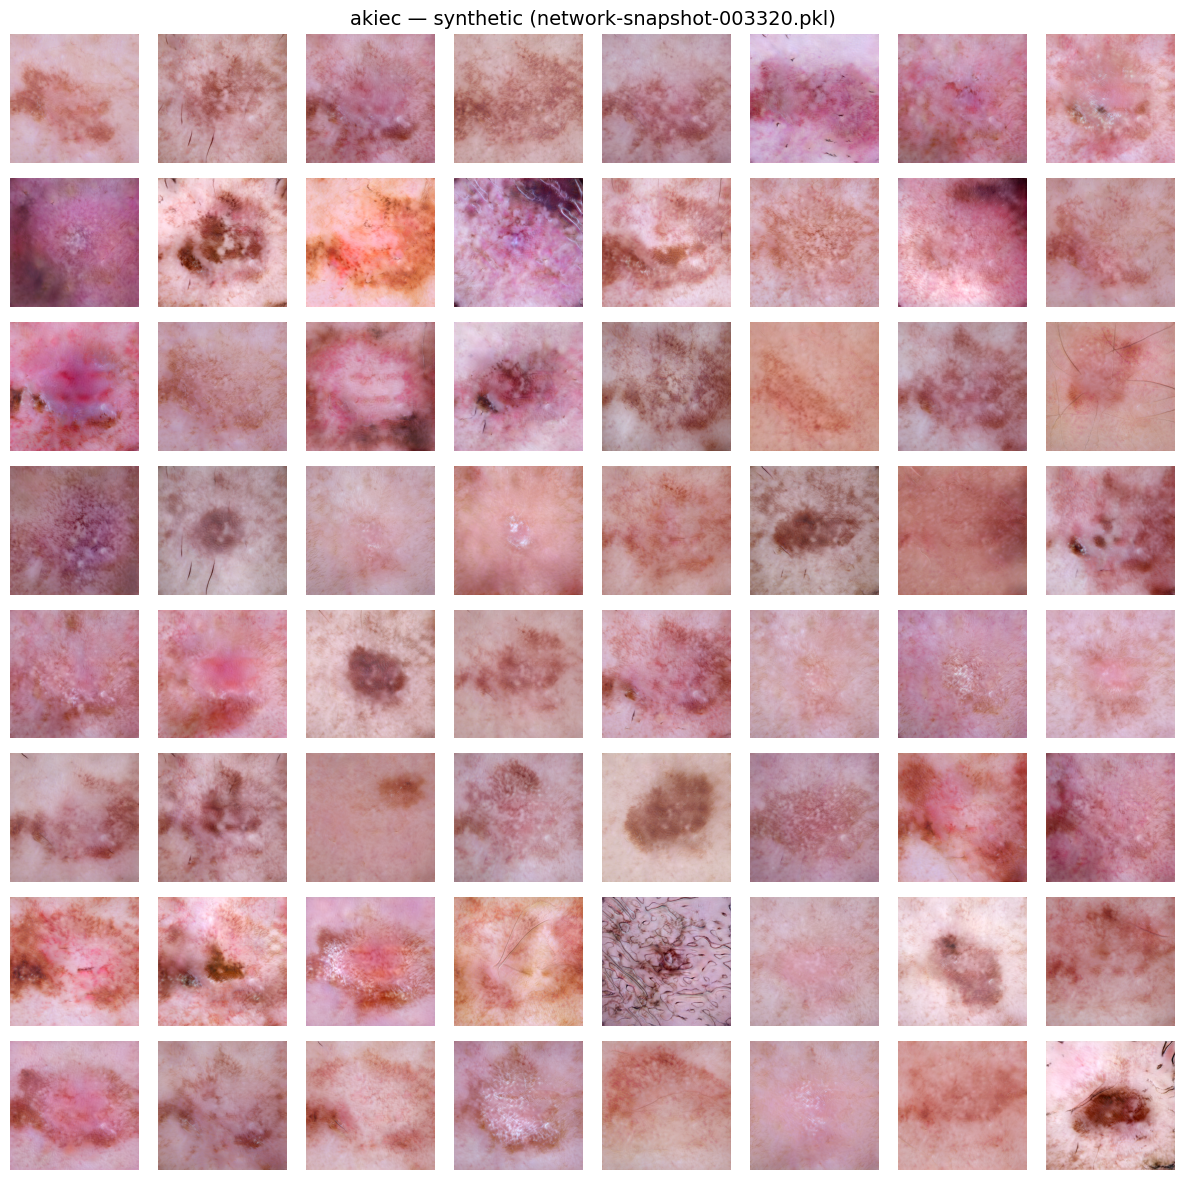

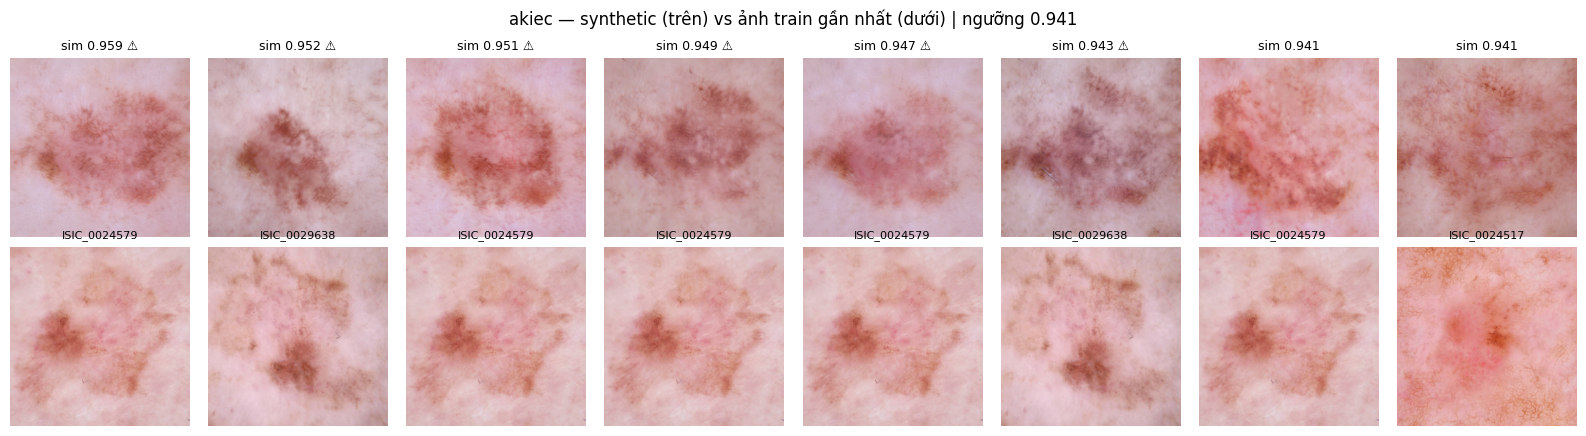

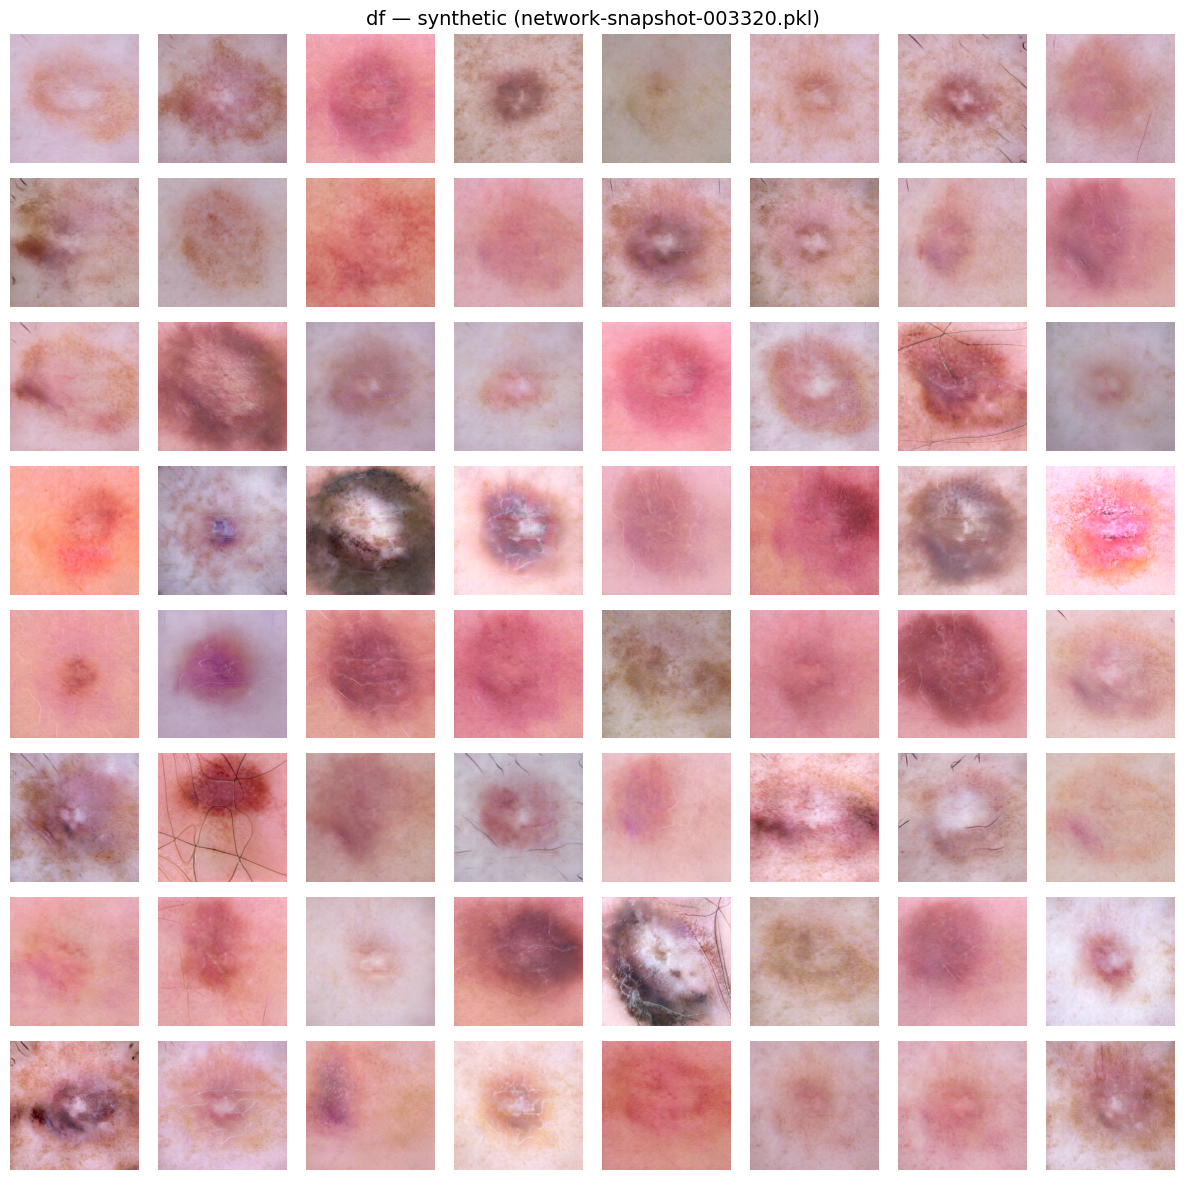

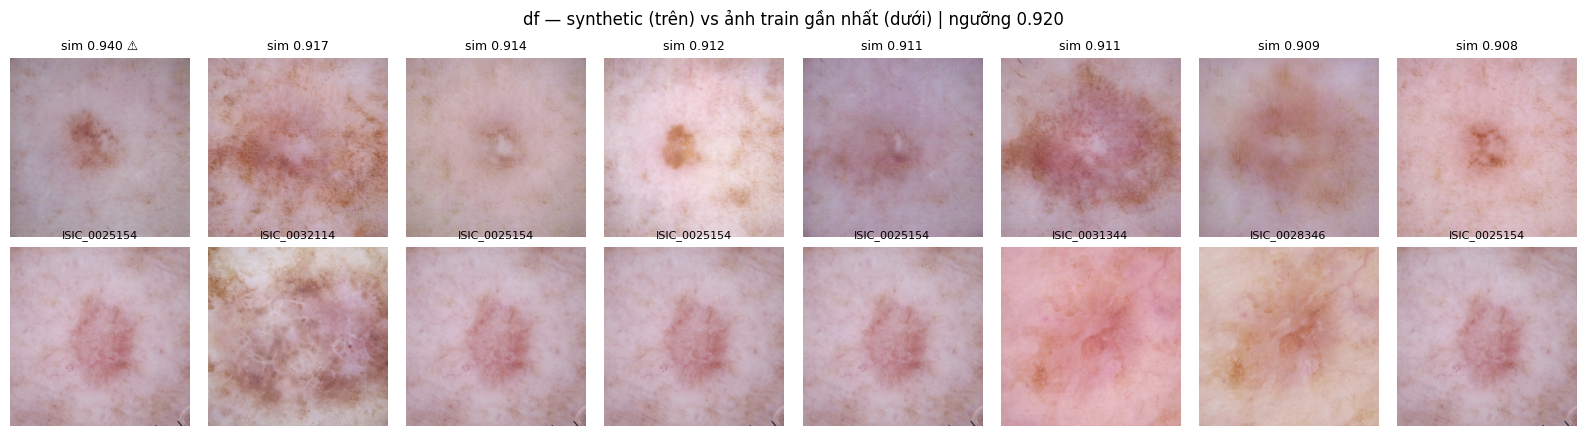

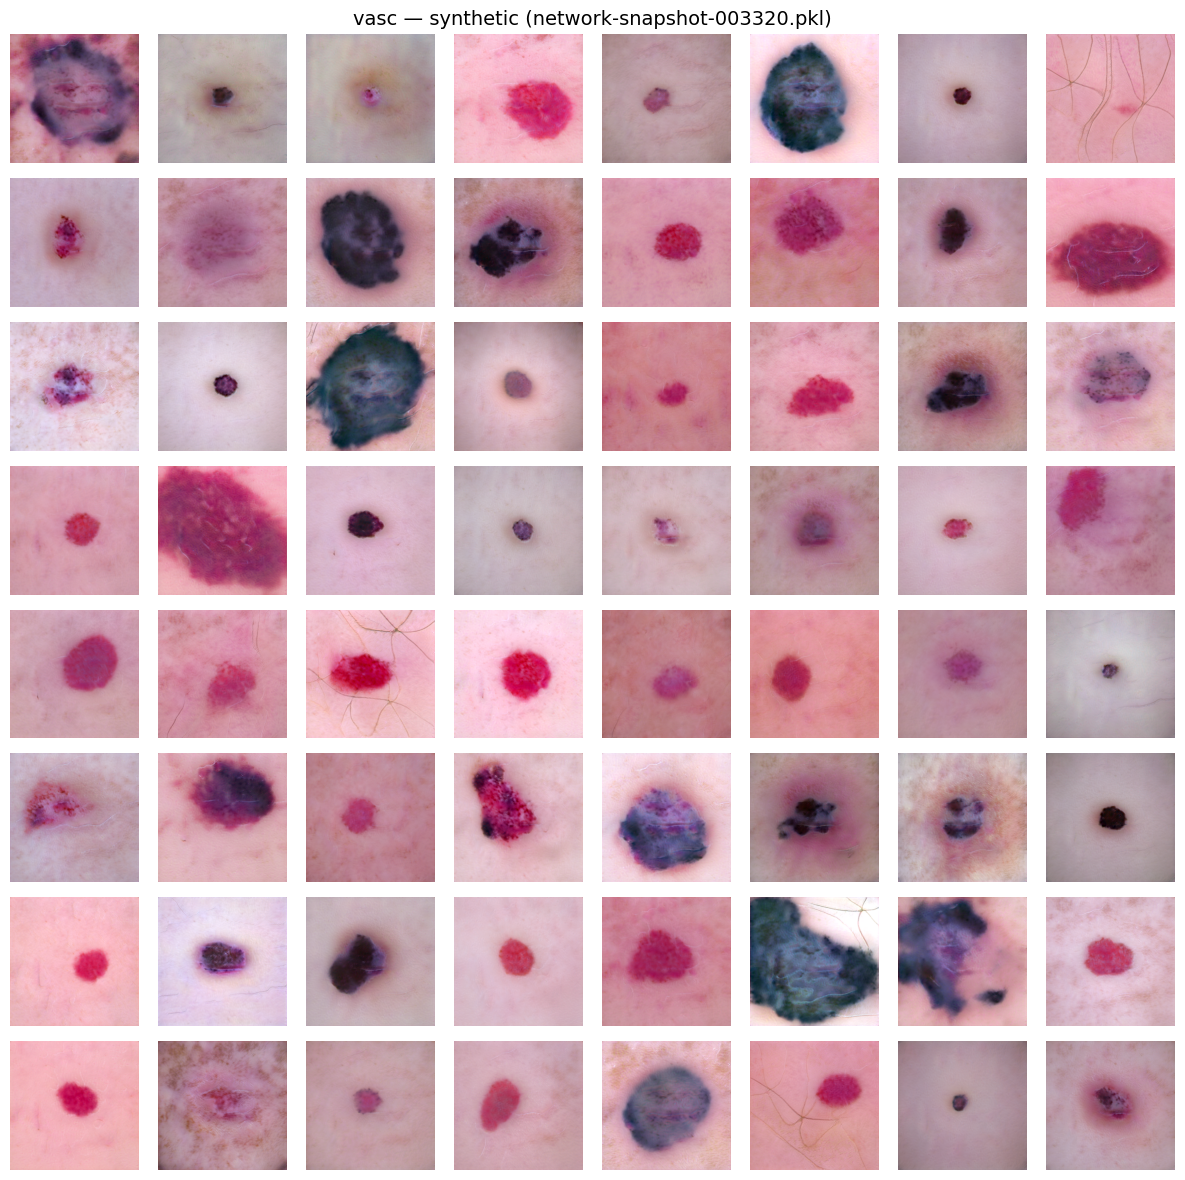

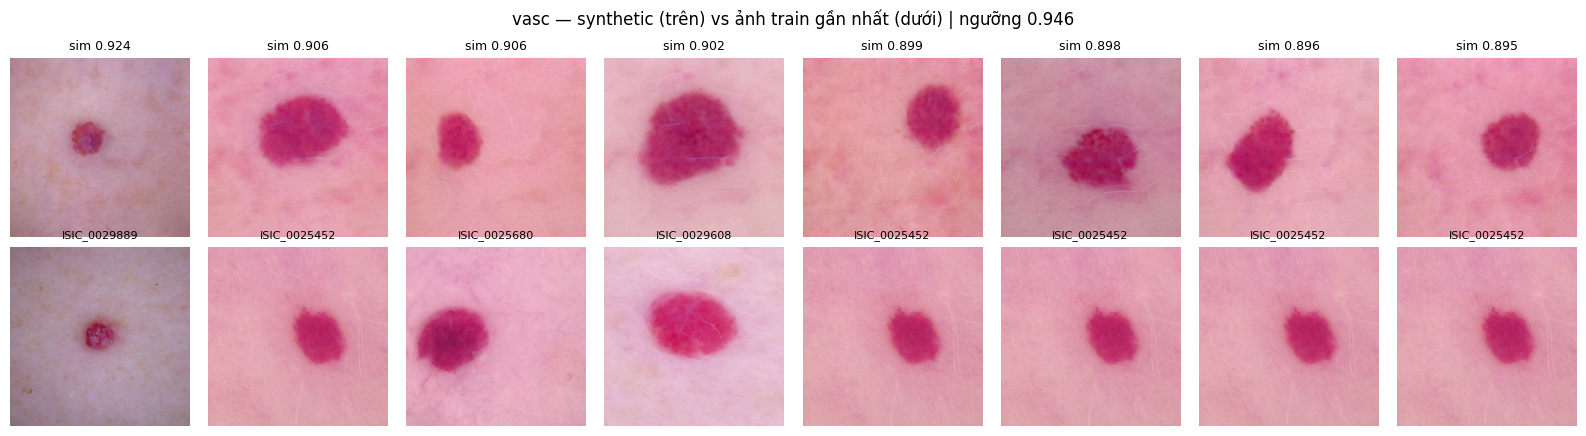

In [ ]:
import matplotlib.pyplot as plt

for dx in MINORITY:
    sub = syn[syn.dx == dx]
    # Lưới 8×8 ảnh giả
    fig, axes = plt.subplots(8, 8, figsize=(12, 12))
    for ax, p in zip(axes.flat, sub.path.head(64)):
        ax.imshow(Image.open(f"{OUT}/{p}")); ax.axis("off")
    fig.suptitle(f"{dx} — synthetic ({snap_name})", fontsize=14)
    plt.tight_layout(); plt.savefig(f"{OUT}/grid_{dx}.png", dpi=70); plt.show()

    # 8 cặp gần nhất: hàng trên = ảnh giả, hàng dưới = ảnh train thật gần nhất
    top = sub.sort_values("nn_sim", ascending=False).head(8)
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
    for j, r in enumerate(top.itertuples()):
        axes[0, j].imshow(Image.open(f"{OUT}/{r.path}"));            axes[0, j].set_title(f"sim {r.nn_sim:.3f}" + ("[CAUTION]" if r.flag_memorized else ""), fontsize=9)
        axes[1, j].imshow(Image.open(f"{real_dir}/{r.nn_image_id}.png")); axes[1, j].set_title(r.nn_image_id, fontsize=8)
        axes[0, j].axis("off"); axes[1, j].axis("off")
    fig.suptitle(f"{dx} — synthetic (trên) vs ảnh train gần nhất (dưới) | ngưỡng {thresholds[dx]:.3f}")
    plt.tight_layout(); plt.savefig(f"{OUT}/nn_pairs_{dx}.png", dpi=70); plt.show()

## 6. Lưu manifest + thông tin generator

In [ ]:
def file_sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

syn.to_csv(f"{OUT}/synthetic_manifest.csv", index=False)
info = {
    "version": VERSION, "created": time.strftime("%Y-%m-%d %H:%M:%S"),
    "generator_snapshot": snap_name, "generator_snapshot_sha256": file_sha(pkl),
    "generator_total_kimg": snap_kimg, "truncation": TRUNC, "seed_base": SEED_BASE,
    "split_manifest_sha256": prep_info["split_manifest_sha256"],
    "gan_train_zip_sha256": prep_info["gan_train_zip_sha256"],
    "res": prep_info["res"], "minority_classes": MINORITY,
    "pool": {"mult": POOL_MULT, "min": MIN_POOL, "extra": EXTRA},
    "feature_extractor": "torchvision resnet50 IMAGENET1K_V2 (penultimate, L2-normalised)",
    "memorization_rule": f"nn_sim > p{NN_PCT} of real-real NN sim between different lesions (same class)",
    "memorization_thresholds": {k: round(v, 4) for k, v in thresholds.items()},
    "prdc_k": K_PRDC, "prdc": prdc_res,
    "quality": {"feature_extractors": list(extractors), "n_boot": N_BOOT, "kid_subsets": KID_SUBSETS,
                "fake_mean_std": {k: [round(m_, 4), round(s_, 4)] for k, (m_, s_) in q_final.items()},
                "reference_real_val_vs_train": {k: round(v, 4) for k, v in REF.items()},
                "detector_auc": {k: round(v, 4) for k, v in det.items()},
                "note": "FID/KID dùng feature torchvision, chỉ so sánh nội bộ. Real val chỉ làm mốc, không dùng test."},
    "counts": syn.groupby("dx").agg(total=("image_id", "size"), flagged=("flag_memorized", "sum")).astype(int).to_dict("index"),
}
json.dump(info, open(f"{OUT}/generator_info.json", "w"), indent=2)
qm_all = pd.concat([qm, pd.DataFrame([{"metric": k, "fake_mean": round(v, 3)} for k, v in det.items()])], ignore_index=True)
qm_all.to_csv(f"{OUT}/quality_metrics.csv", index=False)

summary = syn.groupby("dx").agg(n=("image_id", "size"), flagged=("flag_memorized", "sum"),
                                nn_sim_median=("nn_sim", "median"), nn_sim_max=("nn_sim", "max"))
summary["usable"] = summary.n - summary.flagged
summary["real_train"] = [int((train.dx == d).sum()) for d in summary.index]
summary["max_ratio_usable"] = (summary.usable / summary.real_train).round(2)
display(summary)
print(json.dumps(info["prdc"], indent=2))

,n,flagged,nn_sim_median,nn_sim_max,usable,real_train,max_ratio_usable
dx,,,,,,,
akiec,800,6,0.87255,0.9591,794,222,3.58
df,600,1,0.80755,0.9396,599,71,8.44
vasc,600,0,0.79560,0.9244,600,99,6.06


{
  "akiec": {
    "precision": 0.8262,
    "recall": 0.2658,
    "density": 0.698,
    "coverage": 0.7748
  },
  "df": {
    "precision": 0.9067,
    "recall": 0.2113,
    "density": 0.8047,
    "coverage": 0.9718
  },
  "vasc": {
    "precision": 0.8017,
    "recall": 0.2929,
    "density": 0.6563,
    "coverage": 0.899
  }
}
